In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [49]:
tracks = pd.read_csv(
    "../data/fma_metadata/tracks.csv",
    index_col=0,
    header=[0, 1, 2]
)

features = pd.read_csv(
    "../data/fma_metadata/features.csv",
    index_col=0,
    header=[0, 1, 2]
)

In [50]:
# finding genre column
genre_cols = [
    col for col in tracks.columns
    if "genre_top" in col
]

print(genre_cols)

# counting tracks in each genre
genre_counts = tracks[genre_cols[0]].value_counts()

print(genre_counts)

[('track', 'genre_top', 'Unnamed: 40_level_2')]
(track, genre_top, Unnamed: 40_level_2)
Rock                   14182
Experimental           10608
Electronic              9372
Hip-Hop                 3552
Folk                    2803
Pop                     2332
Instrumental            2079
International           1389
Classical               1230
Jazz                     571
Old-Time / Historic      554
Spoken                   423
Country                  194
Soul-RnB                 175
Blues                    110
Easy Listening            24
Name: count, dtype: int64


## Data Preparation

In [51]:
genre_percentages = (
    genre_counts / genre_counts.sum() * 100
)

print(genre_percentages.round(2))

(track, genre_top, Unnamed: 40_level_2)
Rock                   28.59
Experimental           21.39
Electronic             18.90
Hip-Hop                 7.16
Folk                    5.65
Pop                     4.70
Instrumental            4.19
International           2.80
Classical               2.48
Jazz                    1.15
Old-Time / Historic     1.12
Spoken                  0.85
Country                 0.39
Soul-RnB                0.35
Blues                   0.22
Easy Listening          0.05
Name: count, dtype: float64


Because the dataset is highly imbalanced, I will start with these 8 genres in the FMA Small dataset:
- Rock: 14,182
- Experimental: 10,608
- Electronic: 9,372
- Hip-Hop: 3,552
- Instrumental: 2,079
- Folk: 2,803
- Pop: 2,332
- International: 1,389

In [52]:
#checking for missing vals and if data looks as expected
genre_col = ('track', 'genre_top', 'Unnamed: 40_level_2')

model_data = tracks[[genre_col]].copy()
model_data = model_data.dropna(subset=[genre_col])

mean_features = features.loc[
    :, features.columns.get_level_values(1) == 'mean'
]

model_data = model_data.join(mean_features)

print(model_data.shape)
print(model_data.head())
print(model_data.isna().sum().sum())

(49598, 75)
                  track chroma_cens                                          \
              genre_top        mean                                           
    Unnamed: 40_level_2          01        02        03        04        05   
2               Hip-Hop    0.474300  0.369816  0.236119  0.228068  0.222830   
3               Hip-Hop    0.232784  0.229469  0.225674  0.216713  0.220512   
5               Hip-Hop    0.258420  0.303385  0.250737  0.218562  0.245743   
10                  Pop    0.229882  0.286978  0.240096  0.226792  0.192443   
134             Hip-Hop    0.249513  0.253561  0.262994  0.212424  0.246259   

                                             ... spectral_contrast             \
                                             ...              mean              
           06        07        08        09  ...                06         07   
2    0.221415  0.229238  0.248795  0.196245  ...         17.616112  38.268646   
3    0.242744  0.369235  0.4207

## Train

In [53]:
X = model_data.drop(columns=[genre_col])
y = model_data[genre_col]

#flatten for simpler naming
X.columns = ['_'.join(col) for col in X.columns]

#80/20 train test split for now
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=7,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining genre distribution:")
print(y_train.value_counts())

Training set: (39678, 74)
Testing set: (9920, 74)

Training genre distribution:
(track, genre_top, Unnamed: 40_level_2)
Rock                   11346
Experimental            8486
Electronic              7498
Hip-Hop                 2842
Folk                    2242
Pop                     1866
Instrumental            1663
International           1111
Classical                984
Jazz                     457
Old-Time / Historic      443
Spoken                   338
Country                  155
Soul-RnB                 140
Blues                     88
Easy Listening            19
Name: count, dtype: int64


## Use Decision Tree

In [54]:
model = DecisionTreeClassifier(random_state=7)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Decision Tree accuracy: ", accuracy)

Decision Tree accuracy:  0.4236895161290323


## Evaluate

In [55]:
print(classification_report(y_test, y_pred))

                     precision    recall  f1-score   support

              Blues       0.10      0.14      0.12        22
          Classical       0.54      0.52      0.53       246
            Country       0.18      0.21      0.19        39
     Easy Listening       0.00      0.00      0.00         5
         Electronic       0.43      0.42      0.42      1874
       Experimental       0.42      0.41      0.41      2122
               Folk       0.32      0.32      0.32       561
            Hip-Hop       0.30      0.32      0.31       710
       Instrumental       0.15      0.14      0.15       416
      International       0.18      0.21      0.20       278
               Jazz       0.04      0.04      0.04       114
Old-Time / Historic       0.75      0.77      0.76       111
                Pop       0.10      0.10      0.10       466
               Rock       0.62      0.61      0.62      2836
           Soul-RnB       0.03      0.03      0.03        35
             Spoken    

Observations:
- based on F1 scores, Old-Time / Historic, Rock, and Classical were classified well
- Old-Time / Historic had the highest F1 score, despite it only having 111 test examples - something to investigate

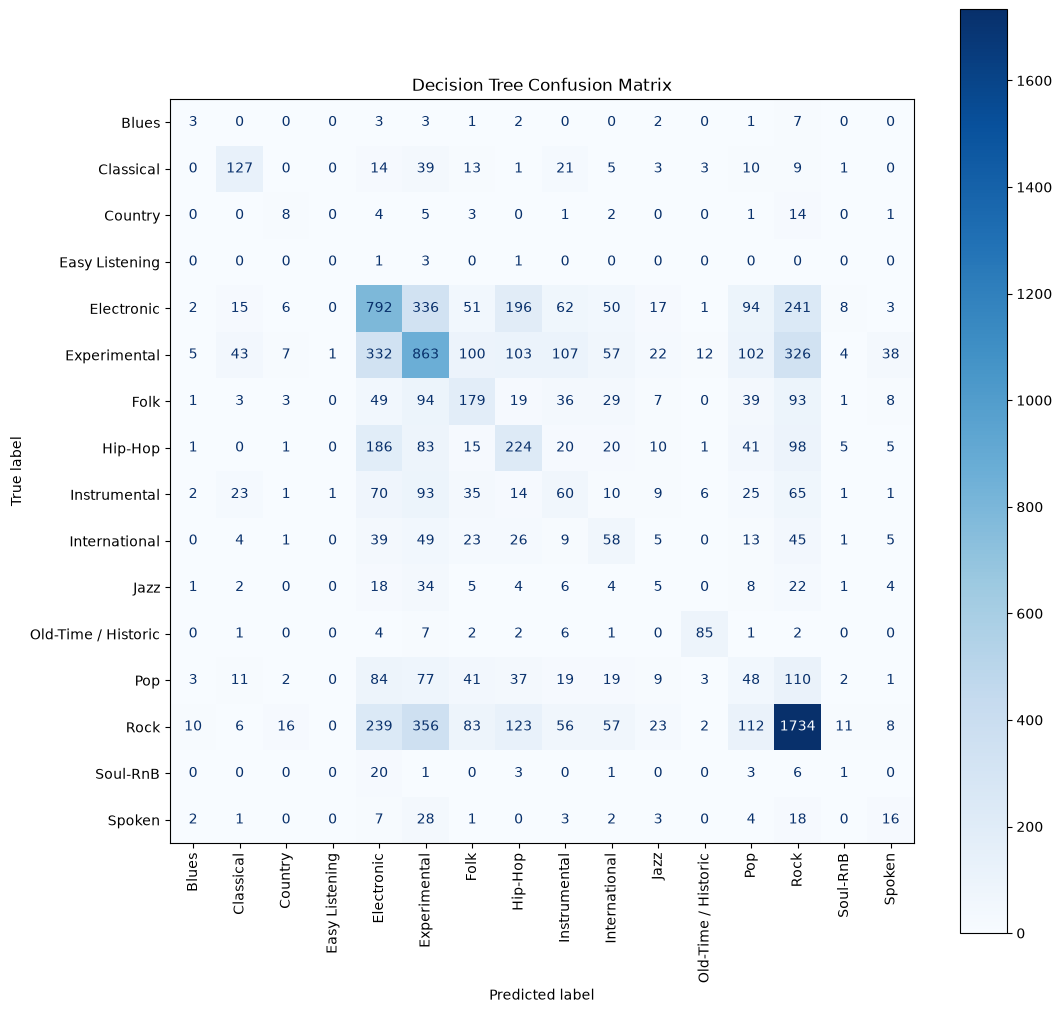

In [56]:
conf_mtx = confusion_matrix(y_test, y_pred, labels=model.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=conf_mtx,
    display_labels=model.classes_
)

fig, ax = plt.subplots(figsize=(12, 12))
disp.plot(ax=ax, xticks_rotation=90, cmap="Blues")
plt.title("Decision Tree Confusion Matrix")
plt.show()

In [57]:
#check for over-fitting bc based on confusion matrix, experimental and rock get confused a lot
train_pred = model.predict(X_train)

print("Training accuracy:", accuracy_score(y_train, train_pred))
print("Testing accuracy:", accuracy_score(y_test, y_pred))

Training accuracy: 0.9988406673723474
Testing accuracy: 0.4236895161290323


### Test out limiting tree depth

In [ ]:
depths = [3, 5, 10, 15, 20]

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=7
    )

    model.fit(X_train, y_train)

    train_accuracy = accuracy_score(y_train, model.predict(X_train))
    test_accuracy = accuracy_score(y_test, model.predict(X_test))

    print(
        f"Depth: {depth}, "
        f"Training: {train_accuracy:.4f}, "
        f"Testing: {test_accuracy:.4f}"
    )

Depth: 3, Training: 0.4336, Testing: 0.4285
Depth: 5, Training: 0.4689, Testing: 0.4560
Depth: 10, Training: 0.5856, Testing: 0.4946
Depth: 15, Training: 0.8203, Testing: 0.4557
Depth: 20, Training: 0.9567, Testing: 0.4415


Analysis:
- Depths 3–5: Training and testing accuracy are relatively close, but the model is probably too simple to capture more complex relationships.

- Depth 10: Testing accuracy reaches its highest value (49.46%). The model captures more useful patterns without overfitting as severely.

- Depths 15–20: Training accuracy increases dramatically, but testing accuracy decreases, clearly overfitting

In [59]:
# try depths around 10
depths = [7, 8, 9, 10, 11, 12, 13]

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_accuracy = accuracy_score(y_train, model.predict(X_train))
    test_accuracy = accuracy_score(y_test, model.predict(X_test))

    print(
        f"Depth: {depth}, "
        f"Training: {train_accuracy:.4f}, "
        f"Testing: {test_accuracy:.4f}"
    )

Depth: 7, Training: 0.5063, Testing: 0.4848
Depth: 8, Training: 0.5244, Testing: 0.4901
Depth: 9, Training: 0.5512, Testing: 0.4882
Depth: 10, Training: 0.5856, Testing: 0.4946
Depth: 11, Training: 0.6254, Testing: 0.4897
Depth: 12, Training: 0.6682, Testing: 0.4816
Depth: 13, Training: 0.7190, Testing: 0.4778


#### Use limited depth as current best Decision Tree

In [60]:
model = DecisionTreeClassifier(
    max_depth=10,
    random_state=7
)

model.fit(X_train, y_train)

y_pred2 = model.predict(X_test)

In [61]:
print(classification_report(y_test, y_pred2))

                     precision    recall  f1-score   support

              Blues       0.00      0.00      0.00        22
          Classical       0.53      0.55      0.54       246
            Country       0.00      0.00      0.00        39
     Easy Listening       0.00      0.00      0.00         5
         Electronic       0.45      0.55      0.49      1874
       Experimental       0.44      0.53      0.48      2122
               Folk       0.40      0.38      0.39       561
            Hip-Hop       0.39      0.24      0.30       710
       Instrumental       0.23      0.04      0.07       416
      International       0.36      0.13      0.19       278
               Jazz       0.00      0.00      0.00       114
Old-Time / Historic       0.86      0.73      0.79       111
                Pop       0.06      0.00      0.01       466
               Rock       0.60      0.74      0.66      2836
           Soul-RnB       0.00      0.00      0.00        35
             Spoken    

/Users/naomizhang/music-genre-classification/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naomizhang/music-genre-classification/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naomizhang/music-genre-classification/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

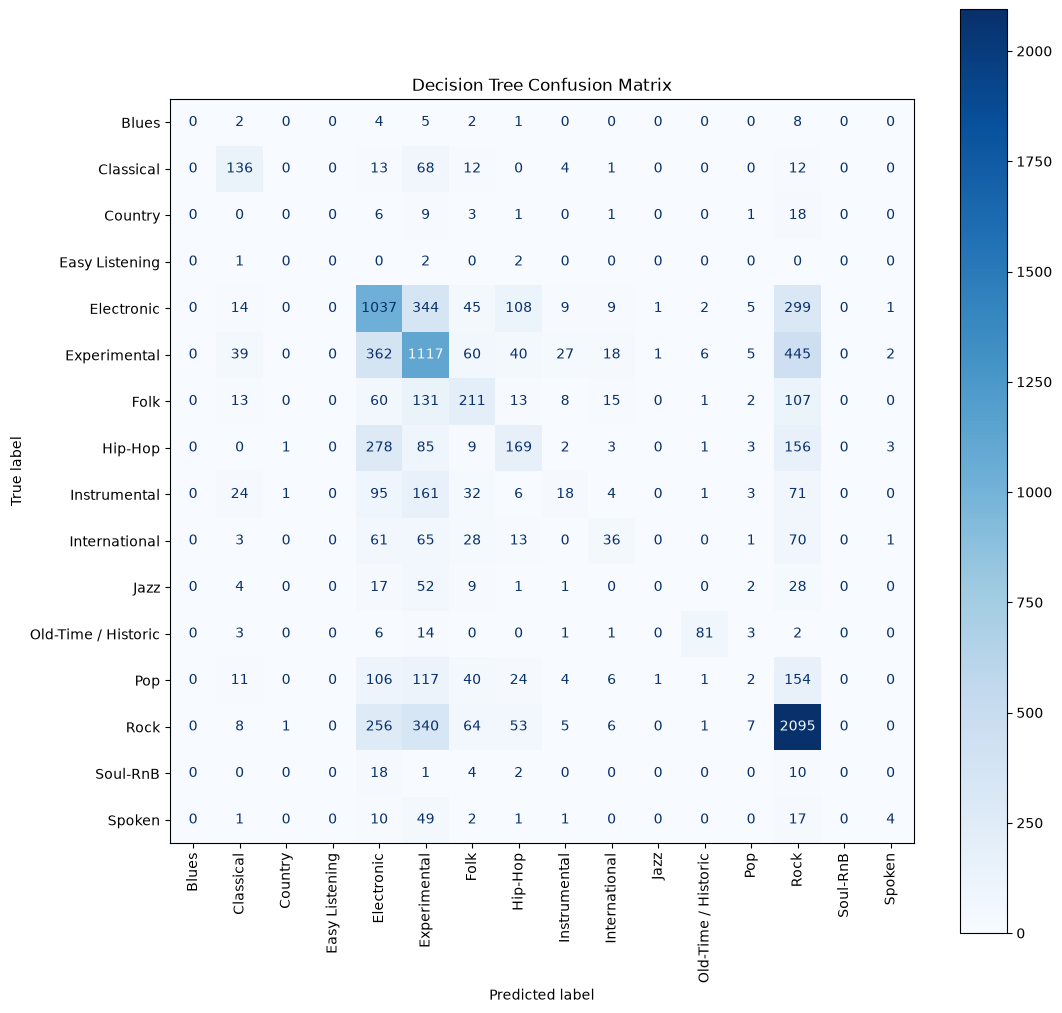

In [62]:
conf_mtx2 = confusion_matrix(y_test, y_pred2, labels=model.classes_)

disp2 = ConfusionMatrixDisplay(
    confusion_matrix=conf_mtx2,
    display_labels=model.classes_
)

fig, ax = plt.subplots(figsize=(12, 12))
disp2.plot(ax=ax, xticks_rotation=90, cmap="Blues")
plt.title("Decision Tree Confusion Matrix")
plt.show()

Decision Tree Model improved predictions overall, but still struggles with less commmon genres.